# 17. Eksperimen single-site dan pooled
**Penelitian:** Deteksi anemia dari citra pucat (telapak tangan, kuku, konjungtiva) dengan data pooling multi-situs.

**Tujuan:** menghitung akurasi, AUC, sensitivitas, spesifisitas, dan confusion matrix untuk Palm, Nail, Conjunctiva, dan data pooled (fitur Original dan Otsu, dengan dan tanpa `site_id`) pada skema 80:20, 80:10:10, dan 70:10:20. Hasil dilaporkan tanpa pembersihan data dan dengan pembersihan (salinan identik dibuang; pasangan citra identik berlabel berbeda dibuang kedua-duanya; citra varian dengan akhiran FV/RA atau spasi+angka yang citra dasarnya ada ikut dibuang bila `BUANG_VARIAN = True`).

**Masukan:** Dataset (Mendeley Data): Palm doi:10.17632/ccr8cm22vz.1, Nail doi:10.17632/2xx4j3kjg2.1, Conjunctiva doi:10.17632/nt7r8hv2pz.1. Letakkan dalam folder `Dataset_Multisite/{Palm,Nail,Conjunctiva}`.

**Keluaran (folder `hasil_revisi`):** `hasil_eksperimen_konsisten.csv` (setiap baris memuat skema, jumlah data uji, TP/TN/FP/FN, dan baseline kelas mayoritas).

**Kaitan dengan naskah:** Bagian 3.9, Tabel 11.

**Cara menjalankan:** Colab, Runtime > Run all. CPU sudah cukup; GPU tidak diperlukan. Seed acak = 42 dan urutan file diurutkan (`sorted`) sehingga hasil dapat direproduksi pada versi pustaka yang dicetak di sel kedua.

In [3]:
!pip install lightgbm -q

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [5]:
# ===== FUNGSI BERSAMA (identik di keempat notebook) =====
import os, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
SEED = 42
BASE = '/content/drive/MyDrive/Dataset_Multisite'   # folder berisi subfolder Palm/, Nail/, Conjunctiva/
OUT  = '/content/drive/MyDrive/hasil_revisi'          # folder keluaran (CSV)
SITES = {'Palm': 0, 'Nail': 1, 'Conjunctiva': 2}
# Filter piksel memeriksa kanal L, R, dan G. Kanal B ikut difilter jika True
# (Appiahene et al. 2023 menuliskan kondisi min < R=G=B < max).
FILTER_INCLUDE_B = False
# True: buang juga citra bernama varian dari citra lain (akhiran FV/RA atau spasi+angka) yang citra dasarnya ada.
BUANG_VARIAN = True
os.makedirs(OUT, exist_ok=True)

# ---------- DAFTAR FILE ----------
def parse_label(name):
    """Label dari awalan nama file (Anemic / Non-Anemic); nama yang mengandung tanda kurung (salinan bernomor) dan awalan tidak dikenali dilewati."""
    if '(' in name: return None
    c = name.lower().replace(' ', '')
    if c.startswith('non-anemic'): return 0
    if c.startswith('anemic'): return 1
    return None

def list_used_files():
    rows = []
    for site, sid in SITES.items():
        d = os.path.join(BASE, site)
        for n in sorted(os.listdir(d)):          # sorted -> urutan deterministik
            lab = parse_label(n)
            if lab is not None:
                rows.append(dict(site=site, site_id=sid, file=n, path=os.path.join(d, n), label=lab))
    return pd.DataFrame(rows)

def md5(path):
    with open(path, 'rb') as f: return hashlib.md5(f.read()).hexdigest()

# ---------- EKSTRAKSI FITUR ----------
def feat_original(img, lo=50, hi=200):
    """Fitur [mean a*, mean b*, mean G] dengan filter piksel. Return (fitur, mask_kosong)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab); R, G, B = cv2.split(rgb)
    m = (L > lo) & (L < hi) & (R > lo) & (R < hi) & (G > lo) & (G < hi)
    if FILTER_INCLUDE_B: m &= (B > lo) & (B < hi)
    if m.any(): return [a[m].mean(), b[m].mean(), G[m].mean()], False
    return [0.0, 0.0, 0.0], True

def feat_otsu(img):
    """Fitur dari piksel foreground Otsu (grayscale). Tanpa filter L/R/G. Return (fitur, mask_kosong)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mk = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = mk > 0
    if not m.any(): return [0.0, 0.0, 0.0], True
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    _, a, b = cv2.split(lab); G = rgb[:, :, 1]
    return [a[m].mean(), b[m].mean(), G[m].mean()], False

# ---------- PEMBAGIAN DATA & EVALUASI ----------
def split_idx(y, scheme, seed=SEED):
    """Return (train, val, test) berupa indeks. Skema: '80:20', '80:10:10', '70:10:20'."""
    idx = np.arange(len(y))
    if scheme == '80:20':
        tr, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        return tr, None, te
    if scheme == '80:10:10':
        tr, tmp = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=seed)
        return tr, va, te
    if scheme == '70:10:20':
        trva, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        tr, va = train_test_split(trva, test_size=0.125, stratify=y[trva], random_state=seed)
        return tr, va, te
    raise ValueError(scheme)

def metrics_from(yte, pred, proba):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(yte), 'TP+TN+FP+FN harus sama dengan jumlah data uji'
    two = len(set(yte)) == 2
    return dict(n_test=len(yte), n_test_anemic=int((yte == 1).sum()), TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
                acc=100*(tp+tn)/len(yte),
                sens=100*tp/(tp+fn) if tp+fn else np.nan,
                spec=100*tn/(tn+fp) if tn+fp else np.nan,
                f1=100*f1_score(yte, pred, zero_division=0),
                auc=100*roc_auc_score(yte, proba) if two else np.nan,
                baseline_mayoritas=100*max((yte == 1).mean(), (yte == 0).mean()))

def fit_lgbm(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    m = LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(sc.transform(Xtr), ytr)
    return sc, m

def predict_lgbm(sc, m, X):
    proba = m.predict_proba(sc.transform(X))[:, 1]
    return (proba >= 0.5).astype(int), proba

def tandai_dibuang(df):
    """Array boolean (urut baris): True bila baris dibuang pada pembersihan = salinan identik MD5 (satu dipertahankan),
    kedua file pada pasangan identik berlabel berbeda, dan (bila BUANG_VARIAN) citra varian FV/RA. df: indeks 0..n-1 dan kolom md5."""
    konflik = df.groupby('md5').label.transform('nunique') > 1
    dibuang = np.array(df.duplicated('md5', keep='first') | konflik, dtype=bool)   # salinan yang dapat diubah
    if BUANG_VARIAN:
        posisi = np.flatnonzero(~dibuang)
        for a, b in pasangan_varian(df.iloc[posisi].reset_index(drop=True)): dibuang[posisi[a]] = True
    return dibuang

def bersihkan(df):
    """Data bersih untuk semua eksperimen (satu definisi tunggal)."""
    df = df.reset_index(drop=True).copy(); df['md5'] = df['path'].map(md5)
    return df[~tandai_dibuang(df)].reset_index(drop=True)

def cek_kebocoran(md5s, tr, va, te, wajib=True):
    """Pemeriksaan kebocoran: indeks latih/validasi/uji harus saling lepas dan tidak ada citra identik (MD5) lintas partisi.
    Return jumlah citra identik lintas partisi, mis. {'latih-uji': 0}. wajib=True -> hentikan program bila ada pelanggaran."""
    parts = {'latih': set(tr), 'uji': set(te)}
    if va is not None: parts['val'] = set(va)
    nm = sorted(parts)
    for i, a in enumerate(nm):
        for b in nm[i + 1:]:
            assert not (parts[a] & parts[b]), f'Indeks tumpang tindih: {a}-{b}'
    m = {k: set(np.asarray(md5s)[sorted(v)]) for k, v in parts.items()}
    bocor = {f'{a}-{b}': len(m[a] & m[b]) for i, a in enumerate(nm) for b in nm[i + 1:]}
    if wajib: assert all(v == 0 for v in bocor.values()), f'Citra identik lintas partisi: {bocor}'
    return bocor

def pasangan_varian(df):
    """Pasangan (indeks varian, indeks citra dasar) pada df (indeks posisi 0..n-1): nama berakhiran FV/RA atau spasi+angka
    yang nama dasarnya ada pada situs yang sama (mis. Anemic-001FV dengan Anemic-001)."""
    stem = df.file.str.replace(r'\.[A-Za-z]+$', '', regex=True)
    base = stem.str.replace(r'\s\d+$', '', regex=True).str.replace(r'(FV|RA)$', '', regex=True)
    key = {(s, t): i for i, (s, t) in enumerate(zip(df.site, stem))}
    return [(i, key[(s, b)]) for i, (s, t, b) in enumerate(zip(df.site, stem, base)) if b != t and (s, b) in key]

def cek_varian(pasangan, tr, va, te):
    """Jumlah pasangan varian-dasar yang terpisah di partisi berbeda (informasi; idealnya 0)."""
    part = {}
    for ids, nm in [(tr, 'latih'), (va, 'val'), (te, 'uji')]:
        if ids is not None:
            for i in ids: part[i] = nm
    return sum(1 for a, b in pasangan if a in part and b in part and part[a] != part[b])

In [6]:
import sys, numpy, pandas, cv2, sklearn, lightgbm
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| OpenCV', cv2.__version__, '| scikit-learn', sklearn.__version__, '| LightGBM', lightgbm.__version__, '| SEED', SEED)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | OpenCV 4.14.0 | scikit-learn 1.6.1 | LightGBM 4.6.0 | SEED 42


In [7]:
# ===== Ekstraksi fitur sekali saja (cache), lalu semua eksperimen memakai fitur yang sama =====
df = list_used_files()
df['md5'] = df['path'].map(md5)
rec = []
for p in df.path:
    img = cv2.imread(p)
    fo, eo = feat_original(img); ft, et = feat_otsu(img)
    rec.append(fo + [eo] + ft + [et])
F = pd.DataFrame(rec, columns=['a_o','b_o','g_o','kosong_o','a_t','b_t','g_t','kosong_t'])
df = pd.concat([df.reset_index(drop=True), F], axis=1)
df['salinan_md5'] = tandai_dibuang(df)      # definisi pembersihan yang sama dengan bersihkan() pada notebook lain
print('Data bersih:', int((~df.salinan_md5).sum()), 'citra', df[~df.salinan_md5].groupby('site').label.agg(total='count', anemic='sum').to_dict('index'))
print('Citra dengan mask kosong (fitur diisi 0): Original =', int(df.kosong_o.sum()), '| Otsu =', int(df.kosong_t.sum()))
print(df.groupby('site').label.agg(['count', 'sum']).rename(columns={'count': 'total', 'sum': 'anemic'}))

Data bersih: 1345 citra {'Conjunctiva': {'total': 514, 'anemic': 291}, 'Nail': {'total': 312, 'anemic': 293}, 'Palm': {'total': 519, 'anemic': 301}}
Citra dengan mask kosong (fitur diisi 0): Original = 39 | Otsu = 0
             total  anemic
site                      
Conjunctiva    547     322
Nail           316     296
Palm           526     304


In [8]:
SCHEMES = ['80:20', '80:10:10', '70:10:20']
def feats(d, kind, with_site):
    cols = ['a_o','b_o','g_o'] if kind == 'Original' else ['a_t','b_t','g_t']
    X = d[cols].to_numpy(float)
    return np.column_stack([X, d.site_id.to_numpy(float)]) if with_site else X

def run(d, tag):
    out = []
    for scheme in SCHEMES:
        # --- single-site ---
        for site in SITES:
            ds = d[d.site == site].reset_index(drop=True); y = ds.label.to_numpy()
            tr, va, te = split_idx(y, scheme)
            bocor = cek_kebocoran(ds.md5.to_numpy(), tr, va, te, wajib=(tag != 'tanpa pembersihan'))
            vlin = cek_varian(pasangan_varian(ds), tr, va, te)
            X = feats(ds, 'Original', False); sc, m = fit_lgbm(X[tr], y[tr]); pr, pb = predict_lgbm(sc, m, X[te])
            out.append(dict(dedup=tag, skema=scheme, eksperimen=f'{site} single-site (Original)', n_train=len(tr), citra_identik_latih_uji=bocor['latih-uji'], varian_lintas_partisi=vlin, **metrics_from(y[te], pr, pb)))
        # --- pooled ---
        dp = d.reset_index(drop=True); y = dp.label.to_numpy()
        tr, va, te = split_idx(y, scheme)
        bocor = cek_kebocoran(dp.md5.to_numpy(), tr, va, te, wajib=(tag != 'tanpa pembersihan'))
        vlin = cek_varian(pasangan_varian(dp), tr, va, te)
        for kind in ['Original', 'Otsu']:
            for ws in [True, False]:
                X = feats(dp, kind, ws); sc, m = fit_lgbm(X[tr], y[tr]); pr, pb = predict_lgbm(sc, m, X[te])
                nm = f'Pooled ({kind}, {"dengan" if ws else "tanpa"} site_id)'
                out.append(dict(dedup=tag, skema=scheme, eksperimen=nm, n_train=len(tr), citra_identik_latih_uji=bocor['latih-uji'], varian_lintas_partisi=vlin, **metrics_from(y[te], pr, pb)))
    return pd.DataFrame(out)

hasil = pd.concat([run(df, 'tanpa pembersihan'), run(df[~df.salinan_md5], 'dengan pembersihan (dedup MD5)')], ignore_index=True)
kolom = ['dedup','skema','eksperimen','n_train','citra_identik_latih_uji','varian_lintas_partisi','n_test','n_test_anemic','TP','TN','FP','FN','acc','sens','spec','f1','auc','baseline_mayoritas']
hasil = hasil[kolom].round(2)
hasil.to_csv(os.path.join(OUT, 'hasil_eksperimen_konsisten.csv'), index=False)
print(hasil.to_string(index=False))

                         dedup    skema                         eksperimen  n_train  citra_identik_latih_uji  varian_lintas_partisi  n_test  n_test_anemic  TP  TN  FP  FN   acc   sens  spec    f1   auc  baseline_mayoritas
             tanpa pembersihan    80:20        Palm single-site (Original)      420                        1                      0     106             61  44  26  19  17 66.04  72.13 57.78 70.97 70.67               57.55
             tanpa pembersihan    80:20        Nail single-site (Original)      252                        0                      0      64             60  58   0   4   2 90.62  96.67  0.00 95.08 77.08               93.75
             tanpa pembersihan    80:20 Conjunctiva single-site (Original)      437                        6                      1     110             65  49  27  18  16 69.09  75.38 60.00 74.24 72.56               59.09
             tanpa pembersihan    80:20  Pooled (Original, dengan site_id)     1111                       14    

In [9]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/hasil_revisi'          # folder berisi CSV hasil
LABEL = ['Non-anemic', 'Anemic']

def cm_dari_baris(r):
    """Matriks [[TN, FP], [FN, TP]]: baris = kelas sebenarnya, kolom = prediksi."""
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
    n = r['n_test'] if 'n_test' in r.index else r['n']
    assert cm.sum() == n, f'TP+TN+FP+FN ({cm.sum()}) harus sama dengan jumlah data ({n})'
    return cm

def gambar_cm(cm, judul, ax):
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100      # persen per kelas sebenarnya
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.1f}%)', ha='center', va='center', fontsize=9,
                    color='white' if pct[i, j] > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABEL, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(LABEL, fontsize=8)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title(judul, fontsize=8)

def grid_cm(df, judul, ncol=4, simpan=None, judul_utama=''):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.4 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        ax.axis('on'); gambar_cm(cm_dari_baris(r), judul(r), ax)
    fig.suptitle(judul_utama); plt.tight_layout()
    if simpan: plt.savefig(os.path.join(OUT, simpan), dpi=150)
    plt.show()

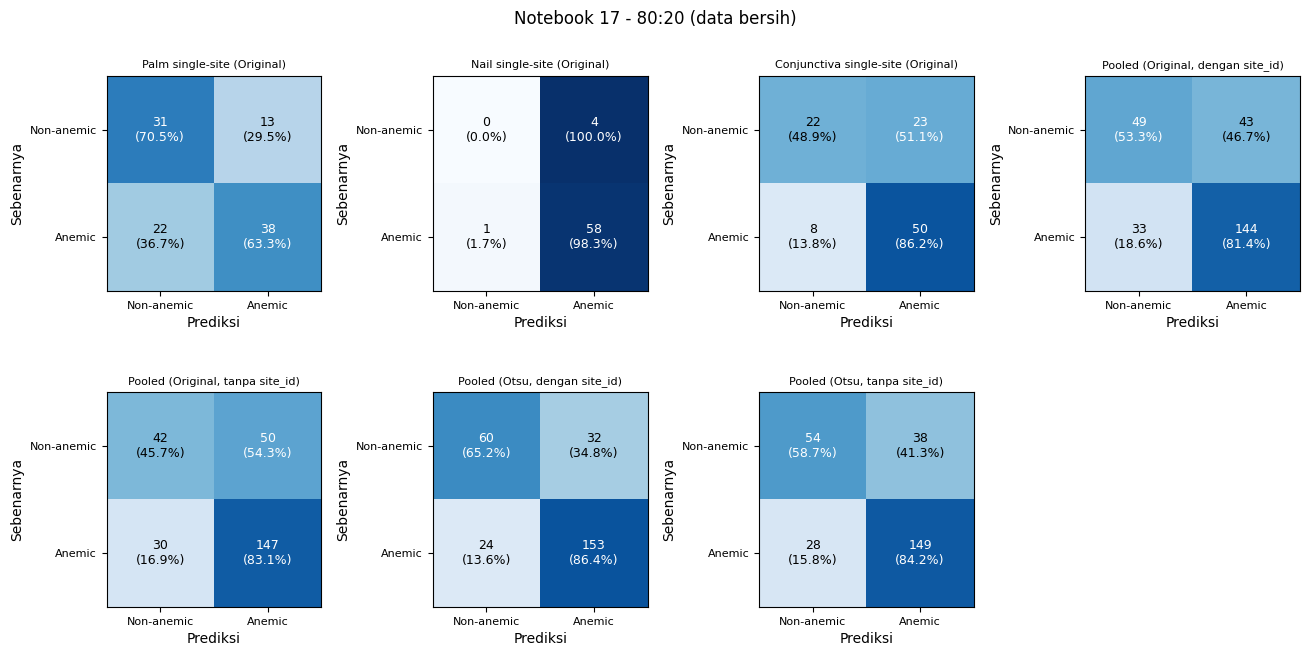

In [10]:
h = pd.read_csv(f'{OUT}/hasil_eksperimen_konsisten.csv')
d = h[(h.dedup == 'dengan pembersihan (dedup MD5)') & (h.skema == '80:20')]    # ganti skema: '80:10:10' atau '70:10:20'
grid_cm(d, lambda r: r['eksperimen'], ncol=4, simpan='cm_nb17_80_20.png', judul_utama='Notebook 17 - 80:20 (data bersih)')